Optimizer         Final train  Final val  Best val  Epochs to val<0.10  Std of val (last 20)
Gradient Descent       0.5092     1.5937    1.5937         not reached               0.05251
SGD                    0.0433     0.2594    0.2594         not reached               0.02523
Momentum               0.0255     0.1250    0.1186         not reached               0.00182
Adam                   0.0224     0.1004    0.0832                   9               0.00063

Lowest final validation loss: Adam


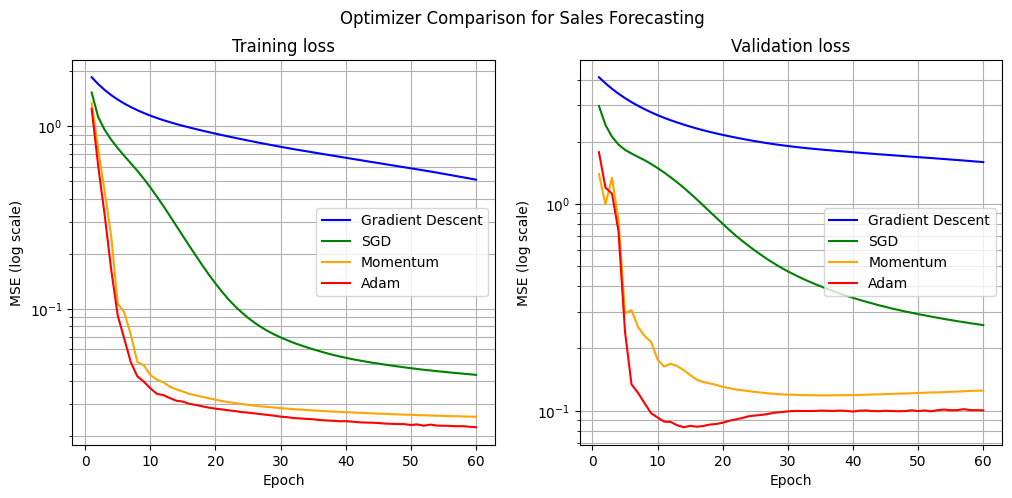

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

np.random.seed(5)

# Step 1: Weekly sales data (3 years = 156 weeks)
weeks = np.arange(156)
price = np.random.uniform(8, 12, 156)
promo = np.random.randint(0, 2, 156).astype(float)
season = np.sin(2 * np.pi * weeks / 52)
sales = 200 + 0.5 * weeks + 40 * season + 30 * promo - 8 * price + np.random.normal(0, 8, 156)
X = np.column_stack([weeks, season, promo, price])
y = sales.reshape(-1, 1)
X = (X - X.mean(axis=0)) / X.std(axis=0)
y = (y - y.mean()) / y.std()
X_train, y_train = X[:112], y[:112]          # first 112 weeks for training
X_val, y_val = X[112:], y[112:]              # last 44 weeks for validation

# Step 2: Same network and same initial weights for every optimizer
def build_model():
    tf.keras.utils.set_random_seed(5)
    return keras.Sequential([
        keras.layers.Input(shape=(4,)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(8, activation="relu"),
        keras.layers.Dense(1)])

settings = {
    "Gradient Descent": (keras.optimizers.SGD(learning_rate=0.01), len(X_train)),
    "SGD": (keras.optimizers.SGD(learning_rate=0.01), 16),
    "Momentum": (keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), 16),
    "Adam": (keras.optimizers.Adam(learning_rate=0.01), 16),
}
epochs = 60
train_loss = np.zeros((4, epochs))
val_loss = np.zeros((4, epochs))
names = list(settings)

for i, name in enumerate(names):
    opt, bs = settings[name]
    model = build_model()
    model.compile(optimizer=opt, loss="mse")
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=epochs, batch_size=bs, shuffle=True, verbose=0)
    train_loss[i] = h.history["loss"]
    val_loss[i] = h.history["val_loss"]

# Step 3: Compare the optimizers using NumPy
print(f"{'Optimizer':17s} {'Final train':>11s} {'Final val':>10s} {'Best val':>9s} "
      f"{'Epochs to val<0.10':>19s} {'Std of val (last 20)':>21s}")
for i, name in enumerate(names):
    r = np.where(val_loss[i] < 0.10)[0]
    ep = int(r[0]) + 1 if len(r) else "not reached"
    print(f"{name:17s} {train_loss[i, -1]:11.4f} {val_loss[i, -1]:10.4f} "
          f"{val_loss[i].min():9.4f} {str(ep):>19s} {np.std(val_loss[i, -20:]):21.5f}")
best = names[int(np.argmin(val_loss[:, -1]))]
print("\nLowest final validation loss:", best)

# Step 4: Plot training and validation loss curves
colors = ["blue", "green", "orange", "red"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, name in enumerate(names):
    axes[0].plot(range(1, epochs + 1), train_loss[i], color=colors[i], label=name)
    axes[1].plot(range(1, epochs + 1), val_loss[i], color=colors[i], label=name)
axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (log scale)")
    ax.set_yscale("log")
    ax.legend()
    ax.grid(True, which="both")
plt.suptitle("Optimizer Comparison for Sales Forecasting")
plt.show()